# Deterministic Global Optimization

A detailed reference for regional bounds, spatial search, convex relaxations and their numerical certificates. The executable examples cover the sine problem, a status-aware αBB prototype, McCormick envelopes and milk pooling. Feasible values, relaxation bounds and exact optimality claims are distinguished throughout.


(go-global-certificates)=
## Feasible values and global certificates

For minimization, a feasible point gives an upper value $U$. A valid global lower value $L$ gives $L\le f^*\le U$. The inequality $U-L\le\epsilon_{\rm gap}$ proves that the supplied point is within that tolerance in **objective value**. It does not bound its distance from every minimizer or establish an exact optimum. A local solver's termination flag alone supplies neither a global lower value nor proof of original feasibility. Check the original bounds and constraints before using its point.

The local-to-global convexity theorem and local KKT/second-order tests have their existing homes in [Optimality](../6/Optimality.ipynb), [Convexity](../7/Convexity.ipynb), and [Second-Order Conditions](../7/Second-Order.ipynb). Spatial search adds a certificate covering unexplored parts of a nonconvex domain. Multistart is a way to find better feasible values; repeated agreement among local solves is not that certificate. The [integer-search reference](MINLP-Algorithms.ipynb#minlp-global-bounds) supplies the common set-inclusion bound argument.

(go-regional-bounds)=
## What a regional relaxation must retain

Let $F_i$ be the original feasible points in box $X_i$, and let a tractable domain $R_i$ contain $F_i$. A convex objective underestimator $f_i^c\le f$ on $F_i$ gives

$$
\ell_i=\inf_{\mathbf{x}\in R_i}f_i^c(\mathbf{x})
\le \inf_{\mathbf{x}\in F_i}f(\mathbf{x}).
$$

The relaxed domain also needs appropriate convex constraints if the subproblem is to be a convex program. A convex objective alone does not convexify an arbitrary retained feasible set. For an inequality $g\le0$, a valid lower function $g^c\le g$ yields the outer row $g^c\le0$. For an equality $h=0$, valid lower/upper functions can yield $h^c\le0\le h^C$. Convex lower and concave upper functions give convex relaxed rows. Arbitrary equality tangents need separate validity conditions; the [MINLP equality-relaxation discussion](MINLP-Algorithms.ipynb#the-broader-bgw-equality-relaxation-variant) gives a counterexample.

Every original-feasible point in $F_i$ gives a regional upper value and an upper value for the whole problem. A regional lower value need not bound other regions. It contributes to a global certificate through a complete cover. A relaxation point itself need not be an original feasible operating plan.

(go-cover-certificate)=
## Coverage, fathoming and tolerance-closed boxes

An incumbent $U$ permits closing a region whose valid lower value satisfies $\ell_i\ge U$ when seeking one optimum: every point there is no better than that incumbent. A certified infeasible outer relaxation also closes a region. A solver failure or a local point that fails to improve $U$ does not. Tied bounds and optimal faces need additional handling when enumerating all optimal points.

Keep every unresolved region in a cover. Children must cover the parent's original feasible points; shared split boundaries are harmless. Unsolved children can inherit a parent lower value. The lower certificate for active boxes $A$ is $\min\{U,\min_{i\in A}\ell_i\}$ when every removed box has lower value at least the incumbent. The incumbent only decreases, so earlier exact bound-based closures stay valid.

If boxes are closed at a tolerance, retain their lower certificates in a set $T$:

$$
L=\min\left\{U,\min_{i\in A}\ell_i,\min_{j\in T}\ell_j\right\},
\qquad L\le f^*\le U.
$$

Empty minima are $+\infty$. This follows by taking the minimum over the regional cover and accounting for the feasible incumbent. Closing a box with $U-\ell_j\le\epsilon_{\rm gap}$ does not prove its value equals $U$. For $U=10$ and a tolerance-closed lower value 9.85, the retained gap is .15 even if all other boxes are bounded above 10 and no active box remains. Dropping that 9.85 would falsely report a zero gap. An iteration limit returns the current interval and a limit status; an empty frontier proves convergence only with the retained certificate.

(go-search-algorithm)=
## A status-aware spatial search

1. Supply a finite initial cover, a positive objective-gap tolerance, and either a checked feasible incumbent or $U=+\infty$.
2. Select a region and compute a valid relaxation lower value. Check solve status before loading results. Preserve an inherited certificate if a solve is interrupted.
3. Close certified infeasibility or a valid bound-based fathoming case. Otherwise attempt a feasible-point heuristic or local solve. Update $U$ only after checking original feasibility.
4. A nonimproving local value leaves the region unresolved. With $\ell_i=0$, incumbent $U=1$, and returned local value 2, the region can still contain a point of value .5.
5. Update the full cover certificate. Stop only with an incumbent and the requested full gap. Retain tolerance-closed lower values if that closure rule is used.
6. Split an unresolved region into children that cover it, generate valid child relaxations and inherit parent lower values. Continue or return an explicit iteration, resolution, or solve limit.

The original 2018 flowchart's $\ell-u\le\epsilon$ test has the wrong direction: it holds automatically when $\ell\le u$. It also returns to region selection after a nonimproving upper solve without retaining/branching the current region. Neither is a correct implementation. The corrected prototype below keeps the cover and interval explicitly. It solves the scalar unconstrained-box example; it is not a general constrained-NLP restoration algorithm.

(go-sine-underestimator)=
## The sine example: verify each affine piece

Use $f(x)=x/4+\sin x$ on $[-3,6]$. The global inequality $\sin x\ge-1$ gives $a_0(x)=x/4-1$. Define the endpoint tangents with their **unrounded** coefficients:

$$
a_t(x)=f(t)+f'(t)(x-t),\qquad f'(t)=1/4+\cos t,
\qquad t\in\{-3,6\}.
$$

These two particular tangents also underestimate $f$ on the entire interval. To verify this without a grid, consider $r_t(x)=f(x)-a_t(x)$. Its derivative vanishes precisely when $\cos x=\cos t$. Check both interval endpoints and every such root in the interval. For $t=-3$, the interior roots are $3$ and $2\pi-3$, and the contact value at $-3$ is zero; the other candidate residuals are positive. For $t=6$, the interior roots are $\pm(2\pi-6)$, the contact value at 6 is zero, and the other candidate residuals are positive. These candidate checks establish nonnegativity throughout each intervening monotonic segment. The complete candidate values are listed below; contact residuals are analytically zero.

Then $f^c(x)=\max\{a_0(x),a_{-3}(x),a_6(x)\}$ is convex and remains below $f$: a maximum of affine functions is convex, and every one of its pieces has the required global validity. A tangent of a general nonconvex function does **not** have this property. At $t=\pi/2$, the tangent is $x/4+1$, which overestimates $f$ by 2 at $x=-\pi/2$. Adding it at a split would invalidate the relaxation.

The left coefficients are approximately $-.7399924966$ and $-3.1110974979$; the right coefficients are $1.2101702867$ and $-6.0404372179$. Printing $-.74x-3.11$ as if it were the exact lower line is unsafe: at $x=-3$ it exceeds $f$ by about .00112. If rounding both slope and intercept, check the full affine perturbation at both domain endpoints, or lower the rounded intercept by its maximum positive perturbation. The numerical calculations below use the unrounded functions. A sampled residual plot is useful evidence of shape, not a global validity proof.

| Tangent at | Residual candidate $x$ | $f(x)-a_t(x)$ |
|---:|---:|---:|
| -3 | -3.000000000 | 0.000000000 |
| -3 | 6.000000000 | 8.771636979 |
| -3 | 3.000000000 | 6.222194996 |
| -3 | 3.283185307 | 6.220306309 |
| 6 | -3.000000000 | 8.779828070 |
| 6 | 6.000000000 | 0.000000000 |
| 6 | -0.283185307 | 6.032927837 |
| 6 | 0.283185307 | 6.047946599 |


(go-sine-search)=
## The three-region example and its actual guarantee

The epigraph LP minimizes $\zeta$ subject to $\zeta\ge a_j(x)$ and the regional interval. Its optimum can also be computed independently by enumerating interval endpoints and pairwise line intersections. On $[-3,6]$ the binding kink is $\bar x=-2.1324378772$ and the lower value is $-1.5331094693$. A local solve initialized on the right finds $x=4.4597087252$, value $.1466813448$; the gap is $1.6797908141$, above .2.

A split at the displayed point 4.46 produces $A=[-3,4.46]$ and $B=[4.46,6]$. On $A$, the original envelope lower value is unchanged. A new feasible point $x=-1.8234765819$ has value $-1.4241149820$, giving a retained gap $.1089944873$. On $B$, minimizing the same envelope gives $\ell_B=.115$ at its left endpoint. Since $.115>U=-1.4241149820$, $B$ can be fathomed without solving its original problem. A separate original solve on $B$ gives about .1466813858, but that is unnecessary for this fathoming decision.

The search certificate is $[-1.5331094693,-1.4241149820]$, whose width is below .2. This is an objective-tolerance guarantee. Separately, for this scalar example one can enumerate $f'=0$, or $\cos x=-1/4$, plus the original interval endpoints; their values establish the exact global minimizer $x^*=-\arccos(-1/4)$ analytically. The small-gap search alone did not prove that exact formula.

Branching at 4.46 is a permissible example choice, not the point of largest underestimation. The error at the relaxed minimizer is about .152, at 4.46 about .032, and the maximum is 2 at $\pi/2$. Nor do these two children require new endpoint tangents: restricting the old valid envelope is already valid. A split by itself does not make an unchanged envelope strictly tighter.

(go-branch-consistency)=
## Why repeated branching needs consistent relaxations

A stopping tolerance alone does not guarantee successful termination. The region selection and splitting rules must preserve the cover and refine relevant regions; the relaxation error must decrease on shrinking boxes. Arbitrary nonconvex tangents can fail validity, and a fixed envelope can retain a nonzero gap indefinitely even as a box shrinks around a point where $f^c<f$.

For the scalar prototype, use

$$
\phi_{[a,b]}(x)=f(x)-\tfrac12(b-x)(x-a).
$$

Since $f''=-\sin x\ge-1$, its second derivative is $1-\sin x\ge0$. It is a convex underestimator on each interval and

$$
0\le f(x)-\phi_{[a,b]}(x)\le (b-a)^2/8.
$$

Thus dyadic midpoint splits quarter this maximum error. At a minimizer of the convex lower function, evaluating the original function supplies a feasible upper value for this unconstrained box. Once every relevant interval width is sufficiently small, its local upper/lower gap is below a fixed positive tolerance. The initial interval is compact, the split depths required by this uniform bound are finite, and the prototype visits unresolved boxes by lower value. Exact finite convergence at zero tolerance is not implied.

In floating-point execution, the convex minimizer is approximate. A tangent to $\phi$ remains valid at any point; minimizing that tangent over $[a,b]$ gives the residual-corrected lower expression

$$
\phi(x_k)+\min\{\phi'(x_k)(a-x_k),\phi'(x_k)(b-x_k)\}.
$$

The code adds explicit small evaluation guards and inherits parent lower certificates. These numerical checks are not formal interval arithmetic. It reports full gaps and limit statuses and retains every tolerance-closed regional lower value.

(go-mccormick-proof)=
## Four products give four valid bilinear rows

Let $x\in[x^L,x^U]$, $y\in[y^L,y^U]$, and lift $w=xy$. Multiplying pairs of nonnegative distances to the bounds gives

$$
\begin{aligned}
w&\ge x^Ly+xy^L-x^Ly^L,&(x-x^L)(y-y^L)&\ge0,\\
w&\ge x^Uy+xy^U-x^Uy^U,&(x^U-x)(y^U-y)&\ge0,\\
w&\le x^Uy+xy^L-x^Uy^L,&(x^U-x)(y-y^L)&\ge0,\\
w&\le x^Ly+xy^U-x^Ly^U,&(x-x^L)(y^U-y)&\ge0.
\end{aligned}
$$

All bound values are constants, so the rows are affine in the lifted variables. They hold for positive, negative, or sign-crossing boxes. The lower maximum is convex; the upper minimum is concave. Together these rows relax the product equality and retain every original graph point. They do not force every relaxed point to satisfy $w=xy$. For $x=y=.5$ in the unit box they allow $0\le w\le.5$, whereas the product is .25.

McCormick (1976), printed p.153, states the two-piece convex envelope. Adjiman et al. (1998), §2.1, pp.1138–1139, displays both lower and upper rows, equations (3)–(4). Use bounds valid for the entire region being relaxed; bounds valid only in one child must not tighten unrelated regions.

(go-mccormick-hull)=
## The single-product hull: an explicit convex-combination proof

For positive box widths normalize $x=x^L+\Delta_x a$, $y=y^L+\Delta_y b$, with $a,b\in[0,1]$. The product lift has the affine transformation

$$
w=x^Ly^L+x^L\Delta_y b+y^L\Delta_x a+\Delta_x\Delta_y q.
$$

For a graph point, $q=ab$. The four envelope rows become $\max(0,a+b-1)\le q\le\min(a,b)$. Every point satisfying them is a convex combination of the four graph corners, using weights

$$
\theta_{00}=1-a-b+q,\quad \theta_{10}=a-q,\quad
\theta_{01}=b-q,\quad\theta_{11}=q.
$$

The rows make these weights nonnegative; they sum to one and reproduce coordinates $(a,b,q)$. Conversely each corner satisfies the rows, and their intersection is convex. This proves the rows describe the convex hull of this **single product graph on its box**. Zero-width cases reduce to an exact affine product and need no normalization.

Replacing many products independently need not give the convex hull of the complete coupled nonlinear model. Shared variables and additional constraints couple the products; their individual hulls can leave a larger joint relaxation. The milk-pooling relaxation below demonstrates a remaining objective gap despite valid product hulls.

(go-mccormick-gaps)=
## Envelope width, product error and objective gap are different

On the normalized unit box,

$$
q^L=\max(0,a+b-1),\quad q^U=\min(a,b),\quad
q^U-q^L=\min\{a,b,1-a,1-b\}.
$$

The widest envelope interval is $1/2$ at the center. Its largest one-sided distance from the actual product is $1/4$:

$$
\max_{[0,1]^2}(ab-q^L)=\max_{[0,1]^2}(q^U-ab)=1/4.
$$

For example, below the line $a+b=1$, the lower error is $ab\le1/4$; above it, it is $(1-a)(1-b)\le1/4$. The upper error follows from $a(1-b)$ when $a\le b$ and its symmetric case. Transforming back multiplies these errors by $\Delta_x\Delta_y$. Thus the maximum envelope width is $\Delta_x\Delta_y/2$, while each maximum product-to-envelope error is $\Delta_x\Delta_y/4$.

Halving one box side halves these maxima; halving both quarters them. Boundary rows are exact. Rebuilding child envelopes makes the child product hull a subset of the parent hull, so a globally minimized **otherwise comparable** child relaxation cannot lower its minimum bound. Improvement need not be strict. The pointwise band formula measures product relaxation error, not the full model's objective optimality gap; objective coefficients, coupling and feasibility also matter.

(go-alphabb-proof)=
## A quadratic underestimator with a uniform curvature condition

For a $C^2$ function on a neighborhood of a finite box and nonnegative parameters $\alpha_i$, define

$$
f_\alpha(\mathbf{x})=f(\mathbf{x})-
\sum_i\alpha_i(x_i^U-x_i)(x_i-x_i^L).
$$

Every subtracted product is nonnegative on the box, so $f_\alpha\le f$. Its Hessian is $\nabla^2f+2\operatorname{diag}(\boldsymbol\alpha)$. Positive semidefiniteness **throughout the box** makes the underestimator convex; evaluating the Hessian only at one point does not establish that condition. A uniform scalar choice $\alpha\ge\max\{0,-\underline\lambda/2\}$ suffices when $\underline\lambda$ is a valid lower bound on all Hessian minimum eigenvalues in the box. An interval Hessian plus a Gershgorin row bound is one way to obtain such a conservative value. Larger values can weaken the relaxation. Adjiman et al. (1998), Theorem 2.1, p.1139, and equation (16)/Theorem 3.2, p.1144, give these conditions.

The error satisfies $0\le f-f_\alpha\le\sum_i\alpha_i\Delta_i^2/4$. For $f(x,y)=xy$ on $[0,1]^2$, choosing $\alpha_x=\alpha_y=.5$ gives a shifted Hessian with eigenvalues 0 and 2. At $(.25,.25)$ this constant-quadratic underestimator is $-.125$, while the McCormick convex envelope is 0. The envelope dominates this convex underestimator by its hull property. This does not mean **every αBB implementation or customized construction** is strictly weaker: the original paper also describes specialized bilinear constructions matching the envelope. Structured secants/envelopes and general quadratic shifts can coexist in one algorithm.

(go-range-reduction)=
## Interval ranges and safe bound tightening

Interval arithmetic propagates enclosures through expressions, with appropriate domain checks and outward rounding for rigorous floating-point use. For $x\in[0,1]$, naively evaluating $x-x$ yields $[-1,1]$ although its exact range is $\{0\}$: dependency can make an enclosure loose. Products must check all endpoint combinations when signs vary; division through an interval containing zero needs separate handling. A narrow observed sample range is not a valid interval enclosure.

Feasibility-based bound tightening propagates constraints and variable bounds. For $x+y\le1$, $x\ge.4$, $y\ge0$, it safely yields $y\le.6$. Optimization-based tightening minimizes and maximizes each coordinate over a valid relaxation. A certified lower value for the minimization gives a safe new lower variable bound; a certified upper value for the maximization gives a safe new upper bound. A local coordinate optimizer or a primal point alone can cut away valid original points. There are up to $2n$ auxiliary optimization problems for a full coordinate pass.

A current incumbent can support objective-based tightening over $f\le U$ when seeking improving points. That restriction preserves potential improvements, rather than every original feasible point. A general solver may mix propagation, optimization and incumbent-based reductions at multiple stages; the simple rule “optimization before search, feasibility at each node” is not a universal restriction. Zhang and Sahinidis (2025), §2.1, pp.1127–1128, describes BARON's branch-and-reduce framework and interval/constraint propagation; §2.3, p.1129, covers factorable reformulation. The scalar prototype here uses explicit interval subdivision and known curvature, not a general range-reduction engine.

(go-reactor-certificate)=
## A concave reactor cost can admit an exact secant certificate

Use the existing [reactor-model home](../1/IP.ipynb) for the physical model; the global-bound extension uses $x_0=x_1+x_2$ and $.8x_1+(2/3)x_2=10$, all nonnegative, with

$$
C=5.5x_1^{.6}+4x_2^{.6}+5x_0.
$$

The feasible set is a segment, with endpoints $(x_1,x_2)=(12.5,0)$ and $(0,15)$. The cost is concave on it. Endpoint values are about 87.53276 and 95.31023. The canonical course model already adopts conversion $2/3$, consistent with BGW’s quoted 66.7% and endpoint values. Its $x_2=15$ point is feasible. If instead the coefficient is set to the rounded value .67, that is a different exact numerical model: its endpoint is $10/.67=14.925373$ with cost94.87640, and $x_2=15$ violates that variant’s mass balance by .05. Do not combine one coefficient convention with the other model’s certificate.

For a concave scalar power on $[0,M]$, its endpoint chord underestimates it. Replacing each power term by its chord makes a linear objective on this segment. Both chords meet the original functions at both feasible segment endpoints, and the LP selects the cheaper endpoint. Its lower value therefore equals an original-feasible upper value: the global optimum is certified, without spatial branching on this special example. This is a distinct use of the previously taught model, rather than another local-solver derivation. BGW Example 15.3, pp.510–511, supplies the model/rounded comparison; the independent audit checks both coefficient conventions and preserves the canonical $2/3$ choice.

(go-pooling-tools)=
## Pooling bounds and solver evidence

The executable milk example below retains its complete data, original pooling builder, two linear reference cases, 201 fixed-composition LPs, McCormick lifted relaxation, twelve seeded Ipopt starts and the Couenne comparison. It is adapted from Postek, Zocca, Gromicho and Kantor's *Hands-On Mathematical Optimization with Python*; retain the original Jeffrey Kantor/MIT notice with adapted code. Fixed-composition points supply feasible profit values when original balances/specifications pass. Because this is maximization, feasible profits are **lower** bounds on the global maximum and relaxed maximum profits are **upper** bounds.

Three peaks in a sampled profile are observations at that grid resolution, not proof that the continuous value function has exactly three local maxima. A scan does not establish the global value by itself. The all-farms/no-pooling LP removes a restriction and gives a reference upper bound; the local-farms-only model embeds a feasible special case and gives a lower value. The McCormick LP supplies a tighter outer bound. Reoptimizing the true fixed-composition model at a relaxation composition is a feasible-point heuristic, not a recovery of the relaxation's lifted flows.

Global solvers combine valid relaxations, original feasible points, branching and reduction, within their supported modeling and numerical assumptions. BARON uses local NLP and linear/mixed-integer subsolvers; this does not establish that every algorithm taught in the course is embedded in every global solver. The Couenne comparison below checks its termination status and original-model residuals separately. Report solver lower/upper information and tolerance when available; a floating-point solver's success is not an interval-arithmetic proof. The existing [circle-packing notebook](Deterministic_Global_Optimization.ipynb) supplies another nonconvex application and its stored GAMS/NEOS examples. No model is submitted to a remote service by this reference's local checks.
The current Couenne adapter reports optimal termination but stores objective-bound fields as $-\infty,+\infty$. Those fields do not establish an infinite problem gap or actual unboundedness; a finite lower/upper objective certificate is unavailable through this adapter result. The original residual check and returned feasible value are still reported. The independently bounded scalar prototype above provides a complete numerical interval directly.


In [1]:
# This code cell installs packages on Colab

import sys

if "google.colab" in sys.modules:
    !wget "https://raw.githubusercontent.com/ndcbe/optimization/main/notebooks/helper.py"
    import helper

    helper.easy_install()
else:
    sys.path.insert(0, "../")
    import helper

helper.set_plotting_style()

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import pyomo.environ as pyo

# House figure style. On Colab only the notebook is present, so fall back to the raw URL.
STYLE = (
    "https://raw.githubusercontent.com/ndcbe/optimization/main/figures/dowling.mplstyle"
    if "google.colab" in sys.modules
    else "../../figures/dowling.mplstyle"
)
plt.style.use(STYLE)

# Seeded once, here, for the multistart study in part 3.
rng = np.random.default_rng(seed=0)

solver_lp = pyo.SolverFactory("appsi_highs")
solver_nlp = pyo.SolverFactory("ipopt")

## Sine model and a valid affine envelope

$$
\min_{-3\le x\le6} f(x)=x/4+\sin x,\qquad \epsilon_{\rm gap}=.2.
$$

Use $f^c=\max\{x/4-1,a_{-3}(x),a_6(x)\}$, where $a_t(x)=f(t)+f'(t)(x-t)$ uses unrounded coefficients. The complete residual argument above proves these particular endpoint tangents are valid. The code computes them directly; a rounded display line is not substituted into the LP.


In [3]:
def f(x):
    """Objective of the handout's example."""
    return x / 4 + np.sin(x)


def f_prime(x):
    """First derivative of f."""
    return 0.25 + np.cos(x)


def tangent(x0):
    """Slope and intercept of the tangent line to f at x0."""
    slope = f_prime(x0)
    return slope, f(x0) - slope * x0


# The three affine pieces: the sin(x) >= -1 bound, and the two endpoint tangents.
PIECES = [(0.25, -1.0), tangent(-3.0), tangent(6.0)]

for slope, intercept in PIECES:
    print(f"f(x) >= {slope:8.5f} x + {intercept:8.5f}")


def f_under(x, pieces=PIECES):
    """Convex underestimator: the upper envelope of the affine pieces."""
    x = np.asarray(x, dtype=float)
    return np.max([slope * x + intercept for slope, intercept in pieces], axis=0)


# Is it really an underestimator on [-3, 6]? Check on a fine grid.
grid = np.linspace(-3, 6, 200_001)
worst = np.max(f_under(grid) - f(grid))
print(
    f"\nmax(f_under - f) over [-3, 6] = {worst:.3e}  (must be <= 0 to within rounding)"
)
assert worst <= 1e-9, "the piecewise-linear function is NOT an underestimator"
# Complete candidate check for each affine residual, independent of the grid.
for slope, intercept in PIECES[1:]:
    angle = np.arccos(slope-.25)
    candidates = [-3., 6.] + [sign*angle+2*np.pi*k for sign in [-1,1] for k in range(-2,3) if -3 <= sign*angle+2*np.pi*k <= 6]
    residual = min(float(f(x)-slope*x-intercept) for x in candidates)
    assert residual >= -2e-14
print("Both endpoint tangent residuals checked at every stationary point and interval endpoint.")


f(x) >=  0.25000 x + -1.00000
f(x) >= -0.73999 x + -3.11110
f(x) >=  1.21017 x + -6.04044

max(f_under - f) over [-3, 6] = 0.000e+00  (must be <= 0 to within rounding)
Both endpoint tangent residuals checked at every stationary point and interval endpoint.


The endpoint lines are valid on this interval, as shown by the complete residual critical-point check. A new tangent at an arbitrary point of this nonconvex function need not be valid. The maximum of the three valid affine pieces is convex.


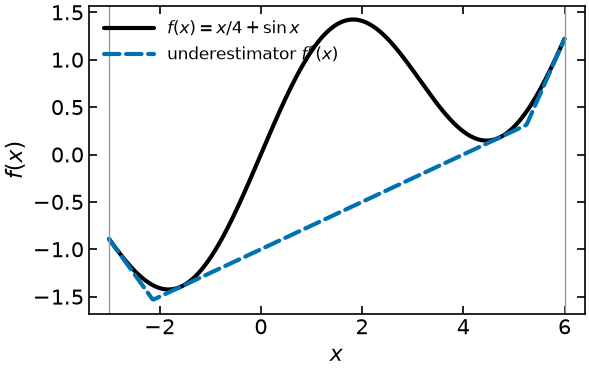

In [4]:
fig, ax = plt.subplots(figsize=(6.4, 4))

x_plot = np.linspace(-3, 6, 400)
ax.plot(x_plot, f(x_plot), label=r"$f(x) = x/4 + \sin x$")
ax.plot(x_plot, f_under(x_plot), label=r"underestimator $f^c(x)$")

ax.axvline(-3, color="0.6", lw=1)
ax.axvline(6, color="0.6", lw=1)
ax.set_xlabel("$x$")
ax.set_ylabel("$f(x)$")
ax.set_xlim(-3.4, 6.4)
ax.legend(loc="upper left")
plt.show()

### Three regional solves

The epigraph LP supplies each regional lower value. The original local solve supplies a value only after its point is checked in that interval. The table below is a demonstration of three solves; the full search invariant and executable search appear in the reference above and prototype below.


In [5]:
def solve_relaxation(lo, hi):
    """Global minimum of the convex underestimator on [lo, hi], as an LP."""
    m = pyo.ConcreteModel("underestimator LP")
    m.x = pyo.Var(bounds=(lo, hi))
    m.t = pyo.Var(domain=pyo.Reals)
    m.PIECES = pyo.RangeSet(0, len(PIECES) - 1)

    @m.Constraint(m.PIECES)
    def epigraph(m, i):
        """Enforce one affine piece of the convex underestimator."""
        slope, intercept = PIECES[i]
        return m.t >= slope * m.x + intercept

    @m.Objective(sense=pyo.minimize)
    def lower_bound(m):
        """Minimize the underestimator epigraph variable."""
        return m.t

    results = solver_lp.solve(m, load_solutions=False)
    assert pyo.check_optimal_termination(
        results
    ), f"relaxation failed: {results.solver.termination_condition}"
    m.solutions.load_from(results)
    return pyo.value(m.x), pyo.value(m.t)


def solve_local(lo, hi, x0):
    """Local minimum of f on [lo, hi], started from x0."""
    m = pyo.ConcreteModel("original problem")
    m.x = pyo.Var(bounds=(lo, hi), initialize=x0)

    @m.Objective(sense=pyo.minimize)
    def obj(m):
        """Minimize the original nonconvex objective locally."""
        return m.x / 4 + pyo.sin(m.x)

    results = solver_nlp.solve(m, options={"bound_relax_factor": 0})
    assert pyo.check_optimal_termination(
        results
    ), f"local solve failed: {results.solver.termination_condition}"
    x = float(np.clip(pyo.value(m.x), lo, hi))
    return x, float(f(x))

In [6]:
EPS = 0.2  # gap tolerance
BRANCH = 4.46  # display-rounded right local point; used consistently in both children

regions = [
    ("1: [-3, 6]", -3.0, 6.0, 5.0),
    ("2: A = [-3, 4.46]", -3.0, BRANCH, 0.7),
    ("3: B = [4.46, 6]", BRANCH, 6.0, 5.2),
]

rows = []
for name, lo, hi, x0 in regions:
    x_lower, l = solve_relaxation(lo, hi)
    x_upper, u = solve_local(lo, hi, x0)
    rows.append(
        {
            "iteration / region": name,
            "x^L": x_lower,
            "l": l,
            "x^U": x_upper,
            "u": u,
            "u - l": u - l,
            "decision": "branch" if u - l > EPS else "within regional tolerance",
        }
    )

iterations = pd.DataFrame(rows).set_index("iteration / region")
display(iterations.round(4))

,x^L,l,x^U,u,u - l,decision
iteration / region,,,,,,
"1: [-3, 6]",-2.1324,-1.5331,4.4597,0.1467,1.6798,branch
"2: A = [-3, 4.46]",-2.1324,-1.5331,-1.8235,-1.4241,0.1090,within regional tolerance
"3: B = [4.46, 6]",4.4600,0.1150,4.4600,0.1467,0.0317,within regional tolerance


The root gap is about 1.680, above .2. On the left child, a better feasible point reduces the gap to about .109. The right child lower value exceeds the updated incumbent and permits fathoming without its original solve. The table includes that extra solve for comparison. A tolerance-qualified regional value is not automatically an exact global optimum.

The branch at 4.46 is a permissible example choice, not the largest relaxation-error point. The maximum error is 2 at $\pi/2$, whereas the error at 4.46 is about .032. Both children reuse the old envelope; adding an arbitrary nonconvex tangent would require a new validity check. The handout revision uses recomputed values rather than inconsistent source rounding.


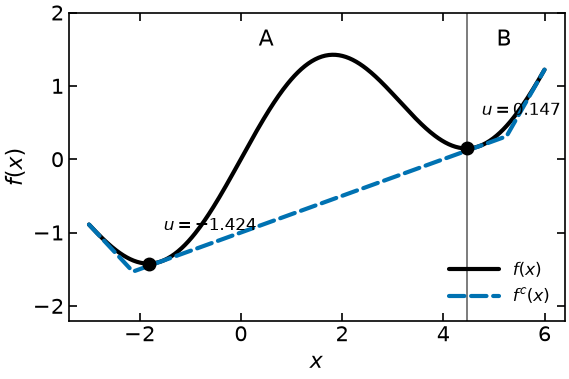

In [7]:
fig, ax = plt.subplots(figsize=(6.4, 4))

ax.plot(x_plot, f(x_plot), label=r"$f(x)$")
ax.plot(x_plot, f_under(x_plot), label=r"$f^c(x)$")

# the two subregions and the accepted solutions
ax.axvline(BRANCH, color="0.4", lw=1.2)
for name, row in iterations.iloc[1:].iterrows():
    ax.plot(row["x^U"], row["u"], marker="o", color="black", ms=9, ls="none")
    ax.annotate(
        f"$u = {row['u']:.3f}$",
        xy=(row["x^U"], row["u"]),
        xytext=(row["x^U"] + 0.3, row["u"] + 0.45),
        fontsize=12,
    )

ax.annotate("A", xy=(0.5, 1.55), fontsize=16, ha="center")
ax.annotate("B", xy=(5.2, 1.55), fontsize=16, ha="center")
ax.set_xlabel("$x$")
ax.set_ylabel("$f(x)$")
ax.set_xlim(-3.4, 6.4)
ax.set_ylim(-2.2, 2.0)
ax.legend(loc="lower right")
plt.show()

## McCormick computations

The four rows and their full hull proof are supplied in the reference above. Here compute the lower/upper envelopes on a unit-box mesh, then compare different box widths and the diagonal section. The band width and the actual product's one-sided error are distinct quantities.


In [8]:
def mccormick_envelopes(X, Y, xl, xu, yl, yu):
    """Lower and upper McCormick envelopes of w = x*y on the box, evaluated on a mesh."""
    lower = np.maximum(xl * Y + X * yl - xl * yl, xu * Y + X * yu - xu * yu)
    upper = np.minimum(xu * Y + X * yl - xu * yl, xl * Y + X * yu - xl * yu)
    return lower, upper


xl, xu, yl, yu = 0.0, 1.0, 0.0, 1.0
gx = np.linspace(xl, xu, 41)
gy = np.linspace(yl, yu, 41)
X, Y = np.meshgrid(gx, gy)
W = X * Y
LO, HI = mccormick_envelopes(X, Y, xl, xu, yl, yu)

print(f"lower envelope violated by at most {np.max(LO - W):.2e}")
print(f"upper envelope violated by at most {np.max(W - HI):.2e}")
print(f"maximum separation HI - LO   = {np.max(HI - LO):.4f}")
print(f"(x^U - x^L)(y^U - y^L) / 2   = {0.5 * (xu - xl) * (yu - yl):.4f}")

lower envelope violated by at most 1.11e-16
upper envelope violated by at most 0.00e+00
maximum separation HI - LO   = 0.5000
(x^U - x^L)(y^U - y^L) / 2   = 0.5000


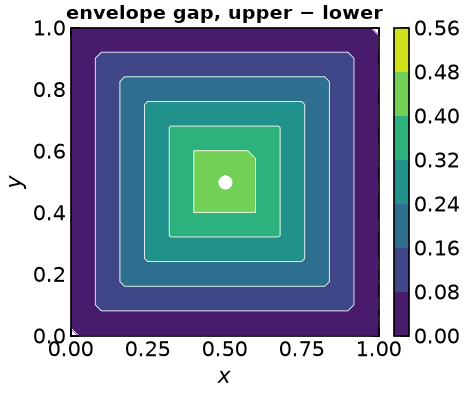

In [9]:
# How far apart the two envelopes are, across the box.
# 7 contour levels, not 20: adjacent bands of any continuous colormap collapse to
# the same grey in print, and 7 keeps them measurably apart.
fig, ax = plt.subplots(figsize=(4.8, 4))
gap = ax.contourf(X, Y, HI - LO, levels=7, cmap="viridis")
ax.contour(X, Y, HI - LO, levels=7, colors="white", linewidths=0.6)
ax.plot(0.5, 0.5, marker="o", color="white", mec="white", ms=9, ls="none")
ax.set_xlabel("$x$")
ax.set_ylabel("$y$")
ax.set_title("envelope gap, upper $-$ lower", fontsize=14)
ax.set_aspect(1)
fig.colorbar(gap, ax=ax, fraction=0.046, pad=0.04)
plt.show()

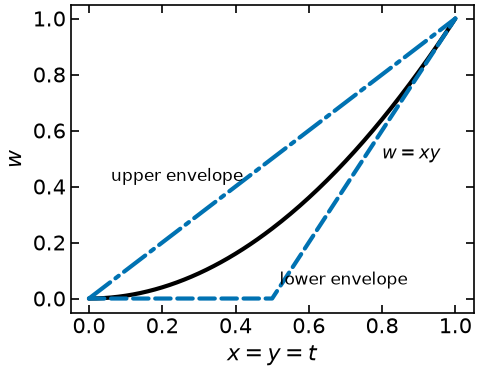

In [10]:
# The same picture along the diagonal x = y = t, where the gap is widest.
fig, ax = plt.subplots(figsize=(5.2, 4))
t = np.linspace(0, 1, 201)
lo_t, hi_t = mccormick_envelopes(t, t, xl, xu, yl, yu)

# both envelopes share one colour and are told apart by linestyle and a direct
# label: they are two halves of one object, not two independent series
ax.plot(t, t * t, color="black", ls="-")
ax.plot(t, hi_t, color="#0072B2", ls="-.")
ax.plot(t, lo_t, color="#0072B2", ls="--")

ax.annotate("$w = xy$", xy=(0.80, 0.50), fontsize=13)
ax.annotate("upper envelope", xy=(0.06, 0.42), fontsize=12)
ax.annotate("lower envelope", xy=(0.52, 0.05), fontsize=12)
ax.set_xlabel("$x = y = t$")
ax.set_ylabel("$w$")
plt.show()

For one bilinear product, the envelopes are exact on every boundary side and describe the graph hull on the box. The largest upper-minus-lower band is half the product of the widths. Each largest one-sided distance from the actual product is a quarter of that product. These are product errors, rather than the complete model’s objective gap. The normalized hull proof above explains the distinction.


In [11]:
boxes = [(0, 1, 0, 1), (0, 2, 0, 1), (-1, 3, 2, 5), (0, 0.5, 0, 0.5)]

rows = []
for xl_, xu_, yl_, yu_ in boxes:
    Xb, Yb = np.meshgrid(np.linspace(xl_, xu_, 401), np.linspace(yl_, yu_, 401))
    lo_b, hi_b = mccormick_envelopes(Xb, Yb, xl_, xu_, yl_, yu_)
    rows.append(
        {
            "box": f"[{xl_}, {xu_}] x [{yl_}, {yu_}]",
            "measured max gap": np.max(hi_b - lo_b),
            "dx * dy / 2": 0.5 * (xu_ - xl_) * (yu_ - yl_),
        }
    )

display(pd.DataFrame(rows).set_index("box").round(6))

,measured max gap,dx * dy / 2
box,,
"[0, 1] x [0, 1]",0.500,0.500
"[0, 2] x [0, 1]",1.000,1.000
"[-1, 3] x [2, 5]",6.000,6.000
"[0, 0.5] x [0, 0.5]",0.125,0.125


The computed maximum envelope widths agree with $\Delta_x\Delta_y/2$. Halving one side halves that maximum; halving both quarters it. Rebuilding a child relaxation can improve its bound, but improvement need not be strict and its complete objective gap must be checked separately.


## Executable scalar spatial search

The known scalar curvature bound makes each αBB subproblem convex. The code retains full-cover lower values, original feasible upper values and explicit limit statuses. Three tolerance targets and two deliberate limit/heuristic cases follow.


In [12]:
import heapq
from scipy.optimize import brentq


def alpha_box_bound(lo, hi):
    """Bound x/4+sin(x) using a convex alphaBB function on a finite interval."""
    if not np.isfinite([lo, hi]).all() or lo > hi:
        raise ValueError('Use a finite ordered interval.')
    alpha = .5  # f''=-sin(x)>=-1; phi''=1-sin(x)>=0 throughout every box.
    phi = lambda x: f(x) - alpha * (hi-x) * (x-lo)
    derivative = lambda x: f_prime(x) + alpha * (2*x-lo-hi)
    if derivative(lo) >= 0:
        x = lo
    elif derivative(hi) <= 0:
        x = hi
    else:
        x = brentq(derivative, lo, hi, xtol=1e-13)
    x = float(np.clip(x, lo, hi))
    slope = float(derivative(x))
    guard = 1e-12 * (1 + abs(phi(x)) + abs(slope) * (hi-lo) + abs(f(x)))
    # A tangent to convex phi is valid even when the root is only approximate.
    lower = float(phi(x) + min(slope*(lo-x), slope*(hi-x)) - guard)
    return {'lo': float(lo), 'hi': float(hi), 'x': x, 'lower': lower,
            'candidate_value': float(f(x)), 'candidate_upper': float(f(x)+guard),
            'slope': slope, 'guard': float(guard)}


def spatial_search(eps=1e-6, max_splits=200, omit_upper_updates=False):
    """Best-bound spatial search with retained bounds for tolerance-closed boxes.

    The omitted-update option deliberately models an unavailable local heuristic:
    the fixed initial feasible point still supplies U; lower bounds cannot simply
    cause a region to disappear after a nonimproving upper evaluation.
    """
    if eps <= 0 or max_splits < 0 or int(max_splits) != max_splits:
        raise ValueError('Use a positive gap tolerance and a nonnegative split cap.')
    initial = alpha_box_bound(-3., 6.)
    nodes = [{**initial, 'node': 0, 'parent': None, 'action': 'active'}]
    queue = [(initial['lower'], 0)]
    retired = []
    best = {'x': 6., 'value': float(f(6.)), 'upper': float(f(6.)+1e-10)}
    history, splits, solved_boxes = [], 0, 1
    status = 'iteration_limit'
    while True:
        if not omit_upper_updates:
            candidate = min(nodes, key=lambda n: n['candidate_upper'])
            if candidate['candidate_upper'] < best['upper']:
                best = {'x': candidate['x'], 'value': candidate['candidate_value'],
                        'upper': candidate['candidate_upper']}
        # Close only certified/tolerance-bounded boxes, retaining their lower values.
        remaining = []
        for lower, index in queue:
            if lower >= best['upper']-eps:
                nodes[index]['action'] = 'tolerance_closed' if lower < best['upper'] else 'fathomed'
                retired.append(lower)
            else:
                remaining.append((lower, index))
        queue = remaining
        heapq.heapify(queue)
        full_lower = min([best['upper']] + retired + [lower for lower,index in queue])
        gap = best['upper'] - full_lower
        history.append({'splits': splits, 'boxes_bounded': solved_boxes,
                        'active': len(queue), 'closed': len(retired),
                        'lower': full_lower, 'upper': best['upper'], 'gap': gap})
        if gap <= eps:
            status = 'converged'
            break
        if splits >= max_splits:
            break
        if not queue:
            status = 'retired_bound_gap'
            break
        parent_lower, index = heapq.heappop(queue)
        parent = nodes[index]
        midpoint = (parent['lo'] + parent['hi'])/2
        if midpoint in (parent['lo'], parent['hi']):
            heapq.heappush(queue, (parent_lower, index))
            status = 'resolution_limit'
            break
        # Build both children before replacing their parent, keeping the coverage.
        children = [alpha_box_bound(parent['lo'], midpoint),
                    alpha_box_bound(midpoint, parent['hi'])]
        parent['action'] = 'branched'
        for child in children:
            # A parent's global lower certificate remains valid on each child.
            child['lower'] = max(parent_lower, child['lower'])
            child_index = len(nodes)
            nodes.append({**child, 'node': child_index, 'parent': index, 'action': 'active'})
            heapq.heappush(queue, (child['lower'], child_index))
        splits += 1
        solved_boxes += 2
    return {'status': status, 'requested_gap': eps, 'best': best,
            'global_lower': full_lower, 'global_gap': gap, 'history': history,
            'nodes': nodes, 'splits': splits, 'boxes_bounded': solved_boxes,
            'numerics': 'Convex tangent/domain bounds with floating-point guards; not interval arithmetic.'}


In [13]:
prototype_runs = []
for tolerance in [.2, 1e-4, 1e-6]:
    run = spatial_search(eps=tolerance)
    assert run['status'] == 'converged' and run['global_gap'] <= tolerance
    prototype_runs.append(run)
    print(f"gap target={tolerance:.0e}: {run['status']}; splits={run['splits']}; "
          f"boxes={run['boxes_bounded']}; x={run['best']['x']:.9f}; "
          f"U={run['best']['upper']:.9f}; L={run['global_lower']:.9f}; gap={run['global_gap']:.3e}")
prototype = prototype_runs[-1]
limited = spatial_search(eps=1e-6, max_splits=1)
assert limited['status'] == 'iteration_limit' and limited['global_gap'] > 1e-6
print(f"one-split cap: {limited['status']}; U={limited['best']['upper']:.6f}; gap={limited['global_gap']:.3e}")
no_update = spatial_search(eps=1e-6, max_splits=1, omit_upper_updates=True)
assert no_update['status'] == 'iteration_limit' and no_update['history'][-1]['active'] > 0
print(f"upper heuristic unavailable: {no_update['status']}; active={no_update['history'][-1]['active']}; "
      f"gap={no_update['global_gap']:.3e}")
results = {'runs': prototype_runs, 'limited': limited, 'no_update': no_update}
helper.save_results('go-spatial-search-actual', results,
    notebook='notebooks/8-dev/Global-Opt.ipynb',
    source_cells=[('notebooks/8-dev/Global-Opt.ipynb', tag) for tag in
                  ['results:go-sine-model', 'results:go-spatial-functions', 'results:go-spatial-runs']],
    description='Actual alphaBB scalar spatial search with full cover bounds and limit statuses',
    solver='SciPy brentq and explicit interval search', quiet=True)


gap target=2e-01: converged; splits=4; boxes=9; x=-1.849699056; U=-1.423782861; L=-1.517560918; gap=9.378e-02
gap target=1e-04: converged; splits=13; boxes=27; x=-1.822861359; U=-1.424114799; L=-1.424139483; gap=2.468e-05
gap target=1e-06: converged; splits=18; boxes=37; x=-1.823419514; U=-1.424114980; L=-1.424115582; gap=6.020e-07
one-split cap: iteration_limit; U=-1.279850; gap=2.389e+00
upper heuristic unavailable: iteration_limit; active=2; gap=4.889e+00


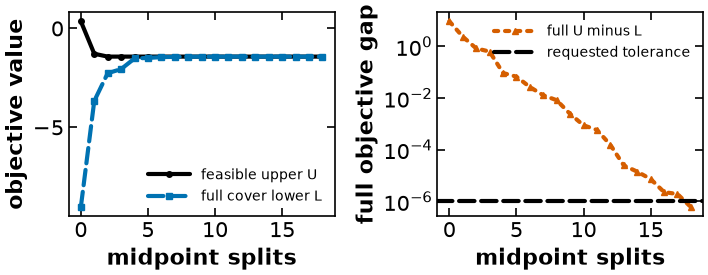

In [14]:
run = results['runs'][-1]
rows = run['history']
fig, axes = plt.subplots(1, 2, figsize=(7.6, 3.0))
k = [r['splits'] for r in rows]
axes[0].plot(k, [r['upper'] for r in rows], 'o-', color='black', markersize=4, label='feasible upper U')
axes[0].plot(k, [r['lower'] for r in rows], 's--', color='#0072B2', markersize=4, label='full cover lower L')
axes[0].set(xlabel='midpoint splits', ylabel='objective value')
axes[0].legend(fontsize=10)
axes[1].semilogy(k, [max(r['gap'], 1e-15) for r in rows], '^:', color='#D55E00', markersize=4, label='full U minus L')
axes[1].axhline(run['requested_gap'], color='black', linestyle='--', label='requested tolerance')
axes[1].set(xlabel='midpoint splits', ylabel='full objective gap')
axes[1].legend(fontsize=10)
fig.tight_layout()
helper.save_figure(fig, 'go-spatial-search-actual', quiet=True)


## 3. Milk pooling

Now a process model. A bulk distributor blends raw milk to meet customer specifications on fat content.
Milk from two **local** farms can be delivered separately, but the two **remote** farms share a single
truck with one tank, so their milk must be mixed into a **pool** of uniform composition $p$ before it
reaches the blending station.

That single sentence is what makes the problem nonconvex. The fat delivered to customer $c$ from the pool
is $p\,y_c$ — pool composition times pool flow — a **bilinear** term, one intensive variable times one
extensive variable. It is the same structure as $w = xy$ in part 2, and it is the reason pooling problems
have been a benchmark for global optimization for nearly fifty years.

:::{note}
**Source and licence.** This example is adapted from *Hands-On Mathematical Optimization with Python* by
Postek, Zocca, Gromicho and Kantor (Cambridge University Press, 2025), notebook 5.1, "Milk pooling and
blending". The MO-book code is MIT-licensed, Copyright (c) 2022 Jeffrey Kantor; that notice travels with
substantial portions of it, and this notebook carries it here. The data and the model are theirs; the
prose is written for this course, and the McCormick relaxation and the global solve are set up to follow
the *Deterministic Global Optimization* handout's notation rather than theirs.

The pooling problem itself is much older: Haverly (1978) is the standard small benchmark, and Misener and
Floudas (2009) survey the literature.
:::

In [15]:
customers = pd.DataFrame(
    {
        "Customer 1": {"min_fat": 0.045, "price": 52.0, "demand": 6000.0},
        "Customer 2": {"min_fat": 0.030, "price": 48.0, "demand": 2500.0},
        "Customer 3": {"min_fat": 0.040, "price": 50.0, "demand": 4000.0},
    }
).T

suppliers = pd.DataFrame(
    {
        "Farm A": {"fat": 0.045, "cost": 45.0, "location": "local"},
        "Farm B": {"fat": 0.030, "cost": 42.0, "location": "local"},
        "Farm C": {"fat": 0.033, "cost": 37.0, "location": "remote"},
        "Farm D": {"fat": 0.050, "cost": 45.0, "location": "remote"},
    }
).T

LOCAL = suppliers.index[suppliers["location"] == "local"].tolist()
REMOTE = suppliers.index[suppliers["location"] == "remote"].tolist()

print("Customers")
display(customers)
print("Suppliers")
display(suppliers)

Customers


,min_fat,price,demand
Customer 1,0.045,52.0,6000.0
Customer 2,0.030,48.0,2500.0
Customer 3,0.040,50.0,4000.0


Suppliers


,fat,cost,location
Farm A,0.045,45.0,local
Farm B,0.03,42.0,local
Farm C,0.033,37.0,remote
Farm D,0.05,45.0,remote


### Two linear reference cases

Before the nonconvex model, two LPs that bracket it.

* **Local farms only** — business as usual. No pool, no bilinear term.
* **Every farm, no pooling** — what the distributor could earn with a second truck, so that remote milk
  arrives unmixed. This *relaxes* the pooling restriction, so it is an upper bound on the pooling profit.

Both are ordinary blending LPs: buy from each source, deliver to each customer, respect demand and a
minimum fat fraction.

In [16]:
def build_blending_lp(sources):
    """Blending LP over a given set of supplier names.

    Arguments:
        sources: list of supplier names that can deliver to customers separately

    Returns:
        a Pyomo ConcreteModel
    """
    m = pyo.ConcreteModel("milk blending LP")
    m.S = pyo.Set(initialize=sources)
    m.C = pyo.Set(initialize=customers.index.tolist())

    # z[s, c] = milk shipped from supplier s into the blend for customer c
    m.z = pyo.Var(m.S, m.C, domain=pyo.NonNegativeReals)

    @m.Constraint(m.C)
    def demand(m, c):
        """Limit deliveries to customer c by its demand."""
        return sum(m.z[s, c] for s in m.S) <= customers.loc[c, "demand"]

    @m.Constraint(m.C)
    def fat_spec(m, c):
        """Meet customer c's minimum fat specification."""
        # linear blending: delivered fat >= required fraction * delivered volume
        return sum(suppliers.loc[s, "fat"] * m.z[s, c] for s in m.S) >= customers.loc[
            c, "min_fat"
        ] * sum(m.z[s, c] for s in m.S)

    @m.Objective(sense=pyo.maximize)
    def profit(m):
        """Maximize revenue minus supplier costs."""
        return sum(
            m.z[s, c] * (customers.loc[c, "price"] - suppliers.loc[s, "cost"])
            for s in m.S
            for c in m.C
        )

    return m


reference = {}
for label, sources in [
    ("local farms only", LOCAL),
    ("all farms, no pooling", suppliers.index.tolist()),
]:
    m = build_blending_lp(sources)
    results = solver_lp.solve(m, load_solutions=False)
    assert pyo.check_optimal_termination(
        results
    ), f"{label}: {results.solver.termination_condition}"
    m.solutions.load_from(results)
    reference[label] = pyo.value(m.profit)
    print(f"{label:>24s}: profit = {reference[label]:10,.0f}")

        local farms only: profit =     81,000


   all farms, no pooling: profit =    122,441


### The pooling model

With the pool, let $x_r$ be the milk bought from remote farm $r$, $y_c$ the pooled milk delivered to
customer $c$, $z_{l,c}$ the local milk delivered to customer $c$, and $p$ the fat fraction of the pool:

$$
\begin{aligned}
\max \quad & \sum_{l,c} (\text{price}_c - \text{cost}_l) z_{l,c}
           + \sum_c \text{price}_c\, y_c - \sum_r \text{cost}_r\, x_r \\
\text{s.t.}\quad
& \sum_l z_{l,c} + y_c \le \text{demand}_c && \forall c \\
& \sum_r x_r = \sum_c y_c \\
& \sum_r \text{fat}_r\, x_r = \underbrace{p \sum_c y_c}_{\text{bilinear}} \\
& \underbrace{p\, y_c}_{\text{bilinear}} + \sum_l \text{fat}_l\, z_{l,c}
  \ \ge\ \text{fat}^{\min}_c \Big( \sum_l z_{l,c} + y_c \Big) && \forall c \\
& p\in[P_{\rm LO},P_{\rm HI}],\qquad x_r, y_c, z_{l,c}\ge0.
\end{aligned}
$$

Two bilinear terms, both products of the pool composition with a flow. Everything else is linear.

The build function below takes `p` either as a fixed `Param` — which makes the model an LP — or as a
`Var`, which makes it a nonconvex NLP. Same constraints either way, which is what lets us scan $p$ and
then optimize over it.

The implementation bounds composition by the remote farms’ minimum/maximum fat fractions. With zero pool flow, composition has no effect on fat deliveries; any permitted value represents that empty pool.


In [17]:
P_LO = suppliers.loc[REMOTE, "fat"].min()
P_HI = suppliers.loc[REMOTE, "fat"].max()


def build_pooling(p=None, p_init=None):
    """Milk pooling model in the p-parameterization.

    Arguments:
        p: pool fat fraction. If a float, it is fixed as a Param and the model is an LP.
           If None, p becomes a decision variable and the model is a bilinear NLP.
        p_init: initial value for the p variable (ignored when p is fixed)

    Returns:
        a Pyomo ConcreteModel
    """
    m = pyo.ConcreteModel("milk pooling")
    m.L = pyo.Set(initialize=LOCAL)
    m.R = pyo.Set(initialize=REMOTE)
    m.C = pyo.Set(initialize=customers.index.tolist())

    m.x = pyo.Var(m.R, domain=pyo.NonNegativeReals)  # bought from remote farm r
    m.y = pyo.Var(m.C, bounds=lambda m, c: (0, customers.loc[c, "demand"]))
    m.z = pyo.Var(m.L, m.C, domain=pyo.NonNegativeReals)

    if p is None:
        m.p = pyo.Var(
            bounds=(P_LO, P_HI),
            initialize=0.5 * (P_LO + P_HI) if p_init is None else p_init,
        )
    else:
        m.p = pyo.Param(initialize=p)

    @m.Constraint(m.C)
    def demand(m, c):
        """Limit direct and pooled deliveries to customer c."""
        return sum(m.z[l, c] for l in m.L) + m.y[c] <= customers.loc[c, "demand"]

    @m.Constraint()
    def pool_balance(m):
        """Balance total inflow to and outflow from the pool."""
        return sum(m.x[r] for r in m.R) == sum(m.y[c] for c in m.C)

    @m.Constraint()
    def pool_fat(m):
        """Balance fat entering and leaving the pool."""
        # fat into the pool = fat out of the pool             [bilinear]
        return sum(suppliers.loc[r, "fat"] * m.x[r] for r in m.R) == m.p * sum(
            m.y[c] for c in m.C
        )

    @m.Constraint(m.C)
    def fat_spec(m, c):
        """Meet customer c's minimum fat specification."""
        # fat delivered to customer c meets the specification [bilinear]
        return m.p * m.y[c] + sum(
            suppliers.loc[l, "fat"] * m.z[l, c] for l in m.L
        ) >= customers.loc[c, "min_fat"] * (sum(m.z[l, c] for l in m.L) + m.y[c])

    @m.Objective(sense=pyo.maximize)
    def profit(m):
        """Maximize pooling profit."""
        return (
            sum(
                m.z[l, c] * (customers.loc[c, "price"] - suppliers.loc[l, "cost"])
                for l in m.L
                for c in m.C
            )
            + sum(customers.loc[c, "price"] * m.y[c] for c in m.C)
            - sum(suppliers.loc[r, "cost"] * m.x[r] for r in m.R)
        )

    return m

def pooling_violation(model):
    """Largest original constraint/bound residual, plus a stated row scale."""
    absolute, scaled = 0., 0.
    for variable in model.component_data_objects(pyo.Var):
        value = pyo.value(variable)
        bounds = [pyo.value(b) for b in [variable.lb, variable.ub] if b is not None]
        violation = max([0.] + ([variable.lb-value] if variable.lb is not None else [])
                        + ([value-variable.ub] if variable.ub is not None else []))
        absolute = max(absolute, violation)
        scaled = max(scaled, violation/max([1.,abs(value)]+[abs(b) for b in bounds]))
    for row in model.component_data_objects(pyo.Constraint, active=True):
        value = pyo.value(row.body)
        lower = pyo.value(row.lower) if row.has_lb() else None
        upper = pyo.value(row.upper) if row.has_ub() else None
        bounds = [b for b in [lower,upper] if b is not None]
        violation = max([0.] + ([lower-value] if lower is not None else [])
                        + ([value-upper] if upper is not None else []))
        absolute = max(absolute, violation)
        scaled = max(scaled, violation/max([1.,abs(value)]+[abs(b) for b in bounds]))
    return float(absolute), float(scaled)


### Fixed-composition profile

Fixing the single pool-composition variable makes this model an LP. The 201-value sweep is a sampled diagnostic of its value function; it is not a global optimality certificate.


In [18]:
p_scan = np.linspace(P_LO, P_HI, 201)
profit_scan = np.full_like(p_scan, np.nan)

for i, p in enumerate(p_scan):
    m = build_pooling(p=p)
    results = solver_lp.solve(m, load_solutions=False)
    if pyo.check_optimal_termination(results):
        m.solutions.load_from(results)
        profit_scan[i] = pyo.value(m.profit)
    else:
        print(f"p = {p:.4f}: {results.solver.termination_condition}")


def local_maxima(values):
    """Indices of local maxima of a 1-D array, endpoints included."""
    out = []
    for i in range(len(values)):
        left = values[i - 1] if i > 0 else -np.inf
        right = values[i + 1] if i < len(values) - 1 else -np.inf
        if values[i] >= left and values[i] >= right and values[i] > min(left, right):
            out.append(i)
    return out


maxima = local_maxima(profit_scan)
print("local maxima found by the scan:")
for i in maxima:
    print(f"  p = {p_scan[i]:.4f}   profit = {profit_scan[i]:10,.0f}")

local maxima found by the scan:
  p = 0.0330   profit =    102,833
  p = 0.0400   profit =    100,067
  p = 0.0451   profit =    101,134


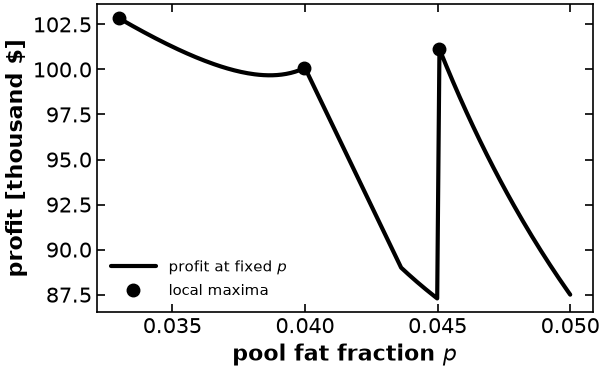

In [19]:
fig, ax = plt.subplots(figsize=(6.4, 4))

ax.plot(p_scan, profit_scan / 1000, label="profit at fixed $p$")
ax.plot(
    p_scan[maxima],
    profit_scan[maxima] / 1000,
    marker="o",
    ls="none",
    color="black",
    ms=9,
    label="local maxima",
)

ax.set_xlabel("pool fat fraction $p$")
ax.set_ylabel("profit [thousand \\$]")
ax.legend(loc="lower left", fontsize=11)
plt.show()

The sampled profile displays three peaks on this 201-point grid. That observation does not prove there are exactly three continuous local maxima or establish a global certificate. Compare the local solves, relaxation and global-solver result below.


### An outer bound from lifted products

Replace $p y_c$ by $w_c$, use the four envelope rows on $p\in[P_{\rm LO},P_{\rm HI}]$ and $y_c\in[0,d_c]$, and retain the linear mass/fat/demand rows. The maximized relaxation gives an upper bound in exact optimization; the reported numerical LP value is interpreted with solver tolerance. It need not be achievable in the original pooling model.


In [20]:
def build_pooling_mccormick():
    """McCormick relaxation of the pooling model: an LP upper bound on the profit."""
    m = build_pooling(p=None)

    # w[c] replaces the bilinear product p * y[c]
    m.w = pyo.Var(m.C, domain=pyo.NonNegativeReals)

    # the two constraints containing bilinear terms are rebuilt in terms of w
    m.del_component(m.pool_fat)
    m.del_component(m.fat_spec)

    @m.Constraint()
    def pool_fat(m):
        """Balance pool fat using lifted product variables."""
        return sum(suppliers.loc[r, "fat"] * m.x[r] for r in m.R) == sum(
            m.w[c] for c in m.C
        )

    @m.Constraint(m.C)
    def fat_spec(m, c):
        """Meet customer c's fat specification in lifted form."""
        return m.w[c] + sum(
            suppliers.loc[l, "fat"] * m.z[l, c] for l in m.L
        ) >= customers.loc[c, "min_fat"] * (sum(m.z[l, c] for l in m.L) + m.y[c])

    # McCormick envelopes of w[c] = p * y[c] on [p_lo, p_hi] x [0, demand_c]
    @m.Constraint(m.C)
    def mccormick_lower_1(m, c):
        """Apply the first McCormick lower bound for customer c."""
        return m.w[c] >= m.p.lb * m.y[c] + m.y[c].lb * m.p - m.p.lb * m.y[c].lb

    @m.Constraint(m.C)
    def mccormick_lower_2(m, c):
        """Apply the second McCormick lower bound for customer c."""
        return m.w[c] >= m.p.ub * m.y[c] + m.y[c].ub * m.p - m.p.ub * m.y[c].ub

    @m.Constraint(m.C)
    def mccormick_upper_1(m, c):
        """Apply the first McCormick upper bound for customer c."""
        return m.w[c] <= m.p.ub * m.y[c] + m.y[c].lb * m.p - m.p.ub * m.y[c].lb

    @m.Constraint(m.C)
    def mccormick_upper_2(m, c):
        """Apply the second McCormick upper bound for customer c."""
        return m.w[c] <= m.p.lb * m.y[c] + m.y[c].ub * m.p - m.p.lb * m.y[c].ub

    return m


m_relaxed = build_pooling_mccormick()
results = solver_lp.solve(m_relaxed, load_solutions=False)
assert pyo.check_optimal_termination(
    results
), f"relaxation failed: {results.solver.termination_condition}"
m_relaxed.solutions.load_from(results)

relaxed_profit = pyo.value(m_relaxed.profit)
relaxed_p = pyo.value(m_relaxed.p)
print(f"McCormick upper bound = {relaxed_profit:10,.0f}  at p = {relaxed_p:.4f}")
print(f"best profit seen in the scan = {np.nanmax(profit_scan):10,.0f}")
print(f"remaining gap = {relaxed_profit - np.nanmax(profit_scan):,.0f}")

McCormick upper bound =    111,412  at p = 0.0400
best profit seen in the scan =    102,833
remaining gap = 8,578


The McCormick LP yields a numerical upper bound of about 111,412 on the maximum profit. The best sampled feasible value is about 102,833, leaving a nonzero certificate gap. Reoptimizing the original fixed-composition model at the relaxed composition is a feasible-point heuristic; its flows need not equal the lifted relaxed flows. Spatial branching rebuilds child envelopes and checks the resulting full model bounds.


In [21]:
# What does the relaxation's p actually deliver?
m_at_relaxed_p = build_pooling(p=relaxed_p)
results = solver_lp.solve(m_at_relaxed_p, load_solutions=False)
assert pyo.check_optimal_termination(results), results.solver.termination_condition
m_at_relaxed_p.solutions.load_from(results)
achievable_at_relaxed_p = pyo.value(m_at_relaxed_p.profit)
print(
    f"profit actually achievable at p = {relaxed_p:.4f}: {achievable_at_relaxed_p:,.0f}"
)

profit actually achievable at p = 0.0400: 100,088


### Seeded local solves and original feasibility

Run twelve seeded local NLP solves. Check termination and original residuals separately. Reoptimize the fixed-composition LP at each clipped composition to obtain a checked feasible candidate to the stated numerical tolerance. A local termination flag alone does not certify its global value.


In [22]:
multistart = []
for trial in range(12):
    p0 = rng.uniform(P_LO, P_HI)
    m = build_pooling(p=None, p_init=p0)
    results = solver_nlp.solve(m)
    tc = results.solver.termination_condition
    if pyo.check_optimal_termination(results):
        raw_p, raw_profit = pyo.value(m.p), pyo.value(m.profit)
        raw_absolute, raw_scaled = pooling_violation(m)
        fixed_p = float(np.clip(raw_p, P_LO, P_HI))
        checked = build_pooling(p=fixed_p)
        checked_result = solver_lp.solve(checked, load_solutions=False)
        assert pyo.check_optimal_termination(checked_result)
        checked.solutions.load_from(checked_result)
        checked_absolute, checked_scaled = pooling_violation(checked)
        assert checked_scaled <= 1e-7
        multistart.append({"p start": p0, "p found": fixed_p,
                          "profit": pyo.value(checked.profit), "raw NLP profit": raw_profit,
                          "raw scaled violation": raw_scaled,
                          "checked scaled violation": checked_scaled,
                          "termination": str(tc)})
    else:
        multistart.append({"p start": p0, "p found": np.nan, "profit": np.nan})
        print(f"trial {trial}: {tc}")

multistart = pd.DataFrame(multistart)
display(multistart.round(4))

print("\ndistinct local optima reached:")
display(
    multistart.round(4)
    .groupby("profit")
    .agg(**{"p found": ("p found", "first"), "count": ("p found", "size")})
)

,p start,p found,profit,raw NLP profit,raw scaled violation,checked scaled violation,termination
0,0.0438,0.045,101392.1569,101392.1579,0.0,0.0,optimal
1,0.0376,0.033,102833.3333,102833.3344,0.0,0.0,optimal
2,0.0337,0.033,102833.3333,102833.3344,0.0,0.0,optimal
3,0.0333,0.033,102833.3333,102833.3344,0.0,0.0,optimal
4,0.0468,0.045,101392.1569,101392.1579,0.0,0.0,optimal
5,0.0485,0.040,100088.2353,100088.2363,0.0,0.0,optimal
6,0.0433,0.045,101392.1569,101392.1579,0.0,0.0,optimal
7,0.0454,0.045,101392.1569,101392.1579,0.0,0.0,optimal
8,0.0422,0.045,101392.1569,101392.1579,0.0,0.0,optimal
9,0.0489,0.045,101392.1569,101392.1579,0.0,0.0,optimal



distinct local optima reached:


,p found,count
profit,,
100088.2353,0.040,1
101392.1569,0.045,7
102833.3333,0.033,4


The table records twelve seeded local runs, including their termination conditions. Multiple returned profits show that a local method can settle at different values. Agreement at a few starts would not establish global optimality; original feasibility and a global bound are separate checks.


### Global-solver comparison

Couenne performs spatial branching with convex relaxations and reduction. For this small model, retain its termination result, available objective-bound fields, and original-model residuals. The returned value is a numerical global-solver result with its solve tolerance.


In [23]:
m_global = build_pooling(p=None)
results = pyo.SolverFactory("couenne").solve(m_global)
assert pyo.check_optimal_termination(
    results
), f"couenne: {results.solver.termination_condition}"

global_profit = pyo.value(m_global.profit)
global_absolute, global_scaled = pooling_violation(m_global)
assert global_scaled <= 1e-6
print(f"Couenne original residual: absolute={global_absolute:.3e}, scaled={global_scaled:.3e}")
print(f"Adapter objective-bound fields: lower={results.problem.lower_bound}, upper={results.problem.upper_bound}")
if not np.isfinite([results.problem.lower_bound, results.problem.upper_bound]).all():
    print("Adapter supplies no finite objective-gap certificate; do not interpret these fields as proven unboundedness.")
print(
    f"Couenne returned profit = {global_profit:,.2f} at p = {pyo.value(m_global.p):.4f}"
)

summary = pd.DataFrame(
    [
        ("local farms only (LP)", reference["local farms only"], "achievable"),
        ("Couenne result with pooling", global_profit, "checked feasible"),
        ("best local optimum found by Ipopt", multistart["profit"].max(), "achievable"),
        (
            "worst local optimum found by Ipopt",
            multistart["profit"].min(),
            "achievable",
        ),
        ("McCormick relaxation (LP)", relaxed_profit, "upper bound"),
        (
            "all farms, no pooling (LP)",
            reference["all farms, no pooling"],
            "upper bound",
        ),
    ],
    columns=["case", "profit", "kind"],
).set_index("case")

display(summary.round(1))

Couenne original residual: absolute=9.095e-13, scaled=9.095e-13
Adapter objective-bound fields: lower=-inf, upper=inf
Adapter supplies no finite objective-gap certificate; do not interpret these fields as proven unboundedness.
Couenne returned profit = 102,833.33 at p = 0.0330


,profit,kind
case,,
local farms only (LP),81000.0,achievable
Couenne result with pooling,102833.3,checked feasible
best local optimum found by Ipopt,102833.3,achievable
worst local optimum found by Ipopt,100088.2,achievable
McCormick relaxation (LP),111411.8,upper bound
"all farms, no pooling (LP)",122441.2,upper bound


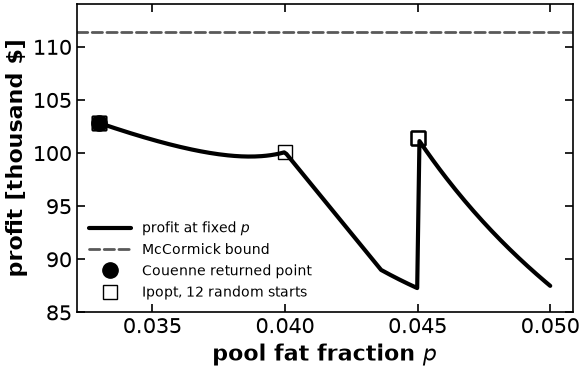

In [24]:
fig, ax = plt.subplots(figsize=(6.4, 4))

ax.plot(p_scan, profit_scan / 1000, label="profit at fixed $p$")
ax.axhline(relaxed_profit / 1000, color="0.35", ls="--", lw=2, label="McCormick bound")
ax.plot(
    pyo.value(m_global.p),
    global_profit / 1000,
    marker="o",
    ls="none",
    color="black",
    ms=11,
    label="Couenne returned point",
)
ax.plot(
    multistart["p found"],
    multistart["profit"] / 1000,
    marker="s",
    ls="none",
    mfc="none",
    mec="black",
    ms=10,
    label="Ipopt, 12 random starts",
)

ax.set_xlabel("pool fat fraction $p$")
ax.set_ylabel("profit [thousand \\$]")
ax.set_ylim(85, 114)
ax.legend(loc="lower left", fontsize=10)
plt.show()

The profit plot combines the sampled feasible profile, local solves and relaxed upper value. The Couenne comparison supplies separate global-solver evidence for this small model; the numerical solver tolerance and original-model residuals limit the claim. The all-farms comparison is an illustrative change in the modeled logistics restriction, not a market valuation or investment recommendation.

## Further reading

* Biegler (2010), §2.3 p.29 and §4.1 p.66, for local/global distinctions.
* BGW (1997), §15.6 p.513, and Example15.3 pp.510–511, for nonconvex process costs.
* McCormick (1976), *Computability of global solutions to factorable nonconvex programs: Part I*, Mathematical Programming10,147–175, p.153.
* [Adjiman, Dallwig, Floudas and Neumaier (1998), αBB Part I](https://doi.org/10.1016/S0098-1354(98)00027-1), §§2.1/2.6, pp.1138–1139, and §3.4, p.1144.
* [Zhang and Sahinidis (2025), Solving continuous and discrete nonlinear programs with BARON](https://doi.org/10.1007/s10589-024-00633-0), §§2.1/2.3, pp.1127–1129.
* Postek, Zocca, Gromicho and Kantor, *Hands-On Mathematical Optimization with Python*, notebook5.1, for the milk-pooling data/model; retain the original MIT attribution.
* [Cornell’s spatial branch-and-bound page](https://optimization.cbe.cornell.edu/index.php?title=Spatial_branch_and_bound_method), the recovered source of the 2018 sine example. Its arithmetic and flowchart require the corrections stated above.
